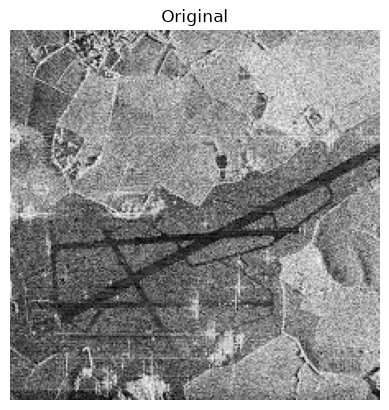

In [26]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import copy
import math

image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')
plt.title('Original')
plt.axis('off')
plt.show()

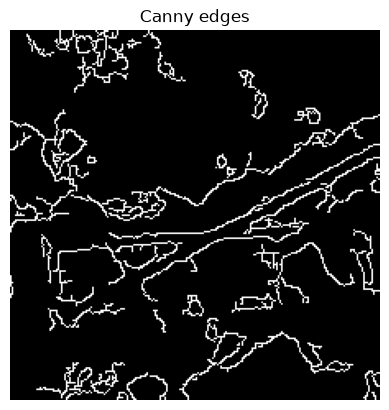

Найдено линий: 2
Длина: 160.6 px
Координаты: (81, 152, 223, 77)


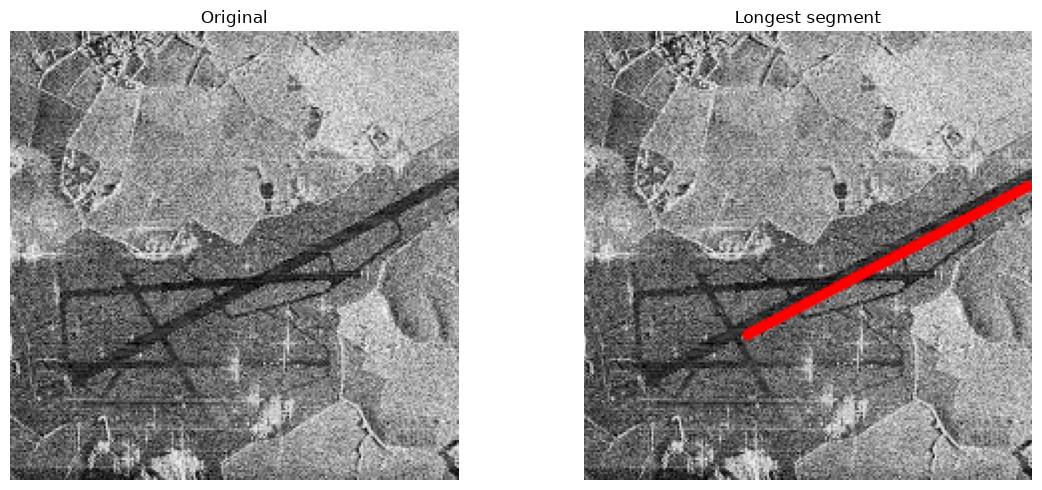

In [27]:
# 1. Самый длинный участок (Хаф)

blurred = cv2.medianBlur(image_gray, 7)

edges = cv2.Canny(blurred, 50, 150, apertureSize=3)
plt.imshow(edges, cmap='gray')
plt.title('Canny edges')
plt.axis('off')
plt.show()

lines = cv2.HoughLinesP(edges, 1, np.pi/180,
                        threshold=70, minLineLength=60, maxLineGap=15)
print('Найдено линий:', 0 if lines is None else len(lines))

lines = np.array(lines).reshape(-1, 4)

best_len = 0
best = None
for x1, y1, x2, y2 in lines:
    length = math.hypot(x2 - x1, y2 - y1)
    if length > best_len:
        best_len = length
        best = (int(x1), int(y1), int(x2), int(y2))
img_lines = image.copy()
if best is not None:
    cv2.line(img_lines, (best[0], best[1]), (best[2], best[3]),
             (0, 0, 255), 3, cv2.LINE_AA)
    print('Длина:', round(best_len, 1), 'px')
    print('Координаты:', best)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray'); plt.title('Original'); plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_lines, cv2.COLOR_BGR2RGB))
plt.title('Longest segment'); plt.axis('off')
plt.tight_layout(); plt.show()

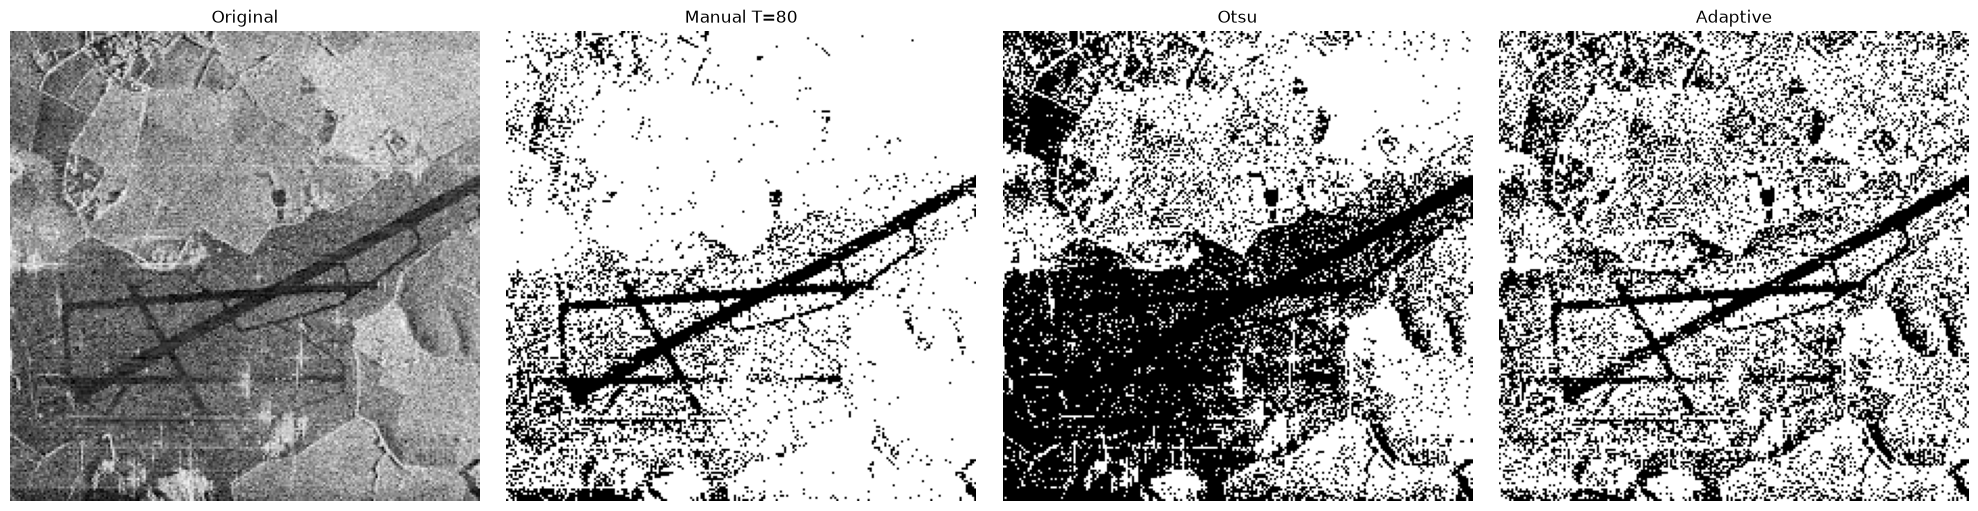

Manual white fraction = 0.831
Otsu white fraction = 0.514
Adaptive white fraction = 0.66


In [28]:
# 2. Бинаризация

T = 80
manual = copy.deepcopy(image_gray)
manual[image_gray < T] = 0
manual[image_gray >= T] = 255

_, otsu = cv2.threshold(image_gray, 0, 255,
                        cv2.THRESH_BINARY + cv2.THRESH_OTSU)

adaptive = cv2.adaptiveThreshold(image_gray, 255,
                                 cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, 71, 15)

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
titles = ['Original', 'Manual T=80', 'Otsu', 'Adaptive']
for a, im, t in zip(ax, [image_gray, manual, otsu, adaptive], titles):
    a.imshow(im, cmap='gray'); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()

for name, bw in [('Manual', manual), ('Otsu', otsu), ('Adaptive', adaptive)]:
    print(name, 'white fraction =', round(np.mean(bw > 0), 3))

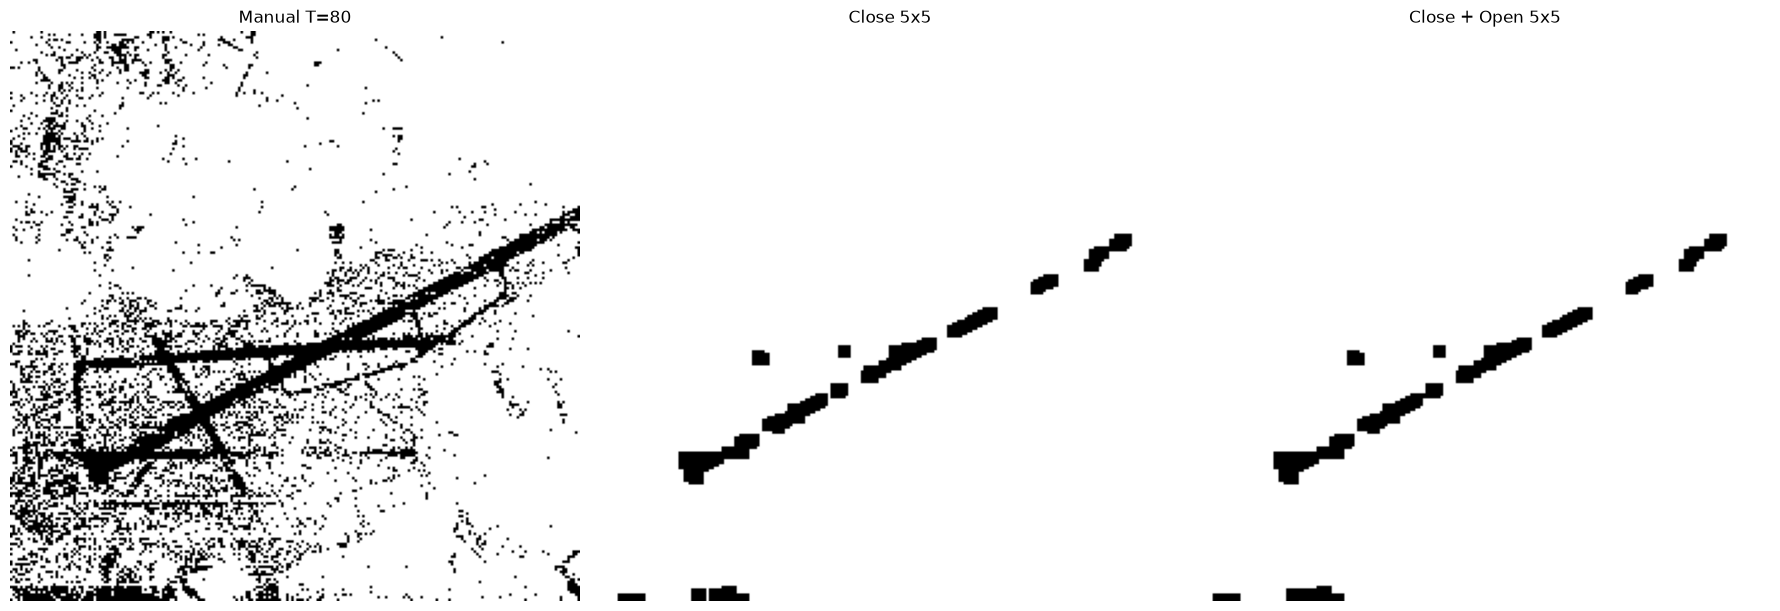

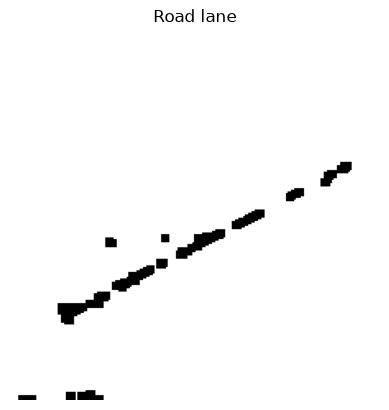

In [29]:
# 2. Дорожная полоса 

closed = cv2.morphologyEx(manual, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
opened = cv2.morphologyEx(closed, cv2.MORPH_OPEN,  np.ones((5, 5), np.uint8))

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(manual, cmap='gray'); ax[0].set_title('Manual T=80')
ax[1].imshow(closed, cmap='gray'); ax[1].set_title('Close 5x5')
ax[2].imshow(opened, cmap='gray'); ax[2].set_title('Close + Open 5x5')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

road = closed
plt.imshow(road, cmap='gray')
plt.title('Road lane')
plt.axis('off')
plt.show()